In [1]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# Suppress non-critical warnings
warnings.filterwarnings('ignore')

# Set aesthetic style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

In [3]:
df = pd.read_csv('Hotel Reservations.csv')

In [4]:
df.shape

(36275, 19)

In [5]:
df.head()

,Booking_ID,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,arrival_year,arrival_month,arrival_date,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status
0,INN00001,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,2017,10,2,Offline,0,0,0,65.00,0,Not_Canceled
1,INN00002,2,0,2,3,Not Selected,0,Room_Type 1,5,2018,11,6,Online,0,0,0,106.68,1,Not_Canceled
2,INN00003,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,2018,2,28,Online,0,0,0,60.00,0,Canceled
3,INN00004,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,2018,5,20,Online,0,0,0,100.00,0,Canceled
4,INN00005,2,0,1,1,Not Selected,0,Room_Type 1,48,2018,4,11,Online,0,0,0,94.50,0,Canceled


In [6]:
# Drop unique identifier if present
if 'Booking_ID' in df.columns:
    df.drop(columns=['Booking_ID'], inplace=True)

# Combine year, month, day safely into a single datetime column
date_cols = ['arrival_year', 'arrival_month', 'arrival_date']
if all(col in df.columns for col in date_cols):
    date_str = (
        df['arrival_year'].astype(str)
        + '-'
        + df['arrival_month'].astype(str).str.zfill(2)
        + '-'
        + df['arrival_date'].astype(str).str.zfill(2)
    )
    # Parse dates safely; unparseable combinations (e.g., Feb 29 non-leap) become NaT
    df['date_of_arrival'] = pd.to_datetime(
        date_str, format='%Y-%m-%d', errors='coerce'
    )
    df.drop(columns=date_cols, inplace=True)

# Drop invalid dates and reset index properly
df.dropna(subset=['date_of_arrival'], inplace=True)
df.reset_index(drop=True, inplace=True)

In [7]:
# Remove invalid bookings with zero adults
df = df[df['no_of_adults'] > 0].reset_index(drop=True)

# Replace invalid room price of 0 with the mean of valid room prices
valid_mean_price = df.loc[
    df['avg_price_per_room'] > 0, 'avg_price_per_room'
].mean()
df['avg_price_per_room'] = df['avg_price_per_room'].replace(
    0, valid_mean_price
)

In [8]:
df.head()

,no_of_adults,no_of_children,no_of_weekend_nights,no_of_week_nights,type_of_meal_plan,required_car_parking_space,room_type_reserved,lead_time,market_segment_type,repeated_guest,no_of_previous_cancellations,no_of_previous_bookings_not_canceled,avg_price_per_room,no_of_special_requests,booking_status,date_of_arrival
0,2,0,1,2,Meal Plan 1,0,Room_Type 1,224,Offline,0,0,0,65.00,0,Not_Canceled,2017-10-02
1,2,0,2,3,Not Selected,0,Room_Type 1,5,Online,0,0,0,106.68,1,Not_Canceled,2018-11-06
2,1,0,2,1,Meal Plan 1,0,Room_Type 1,1,Online,0,0,0,60.00,0,Canceled,2018-02-28
3,2,0,0,2,Meal Plan 1,0,Room_Type 1,211,Online,0,0,0,100.00,0,Canceled,2018-05-20
4,2,0,1,1,Not Selected,0,Room_Type 1,48,Online,0,0,0,94.50,0,Canceled,2018-04-11


In [9]:
print(f'Cleaned Dataset Shape: {df.shape}')
print('\nData Types & Null Counts:')
print(df.info())

Cleaned Dataset Shape: (36099, 16)

Data Types & Null Counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36099 entries, 0 to 36098
Data columns (total 16 columns):
 #   Column                                Non-Null Count  Dtype         
---  ------                                --------------  -----         
 0   no_of_adults                          36099 non-null  int64         
 1   no_of_children                        36099 non-null  int64         
 2   no_of_weekend_nights                  36099 non-null  int64         
 3   no_of_week_nights                     36099 non-null  int64         
 4   type_of_meal_plan                     36099 non-null  object        
 5   required_car_parking_space            36099 non-null  int64         
 6   room_type_reserved                    36099 non-null  object        
 7   lead_time                             36099 non-null  int64         
 8   market_segment_type                   36099 non-null  object        
 9   repeated_g

## Exploratory Data Analysis (EDA)

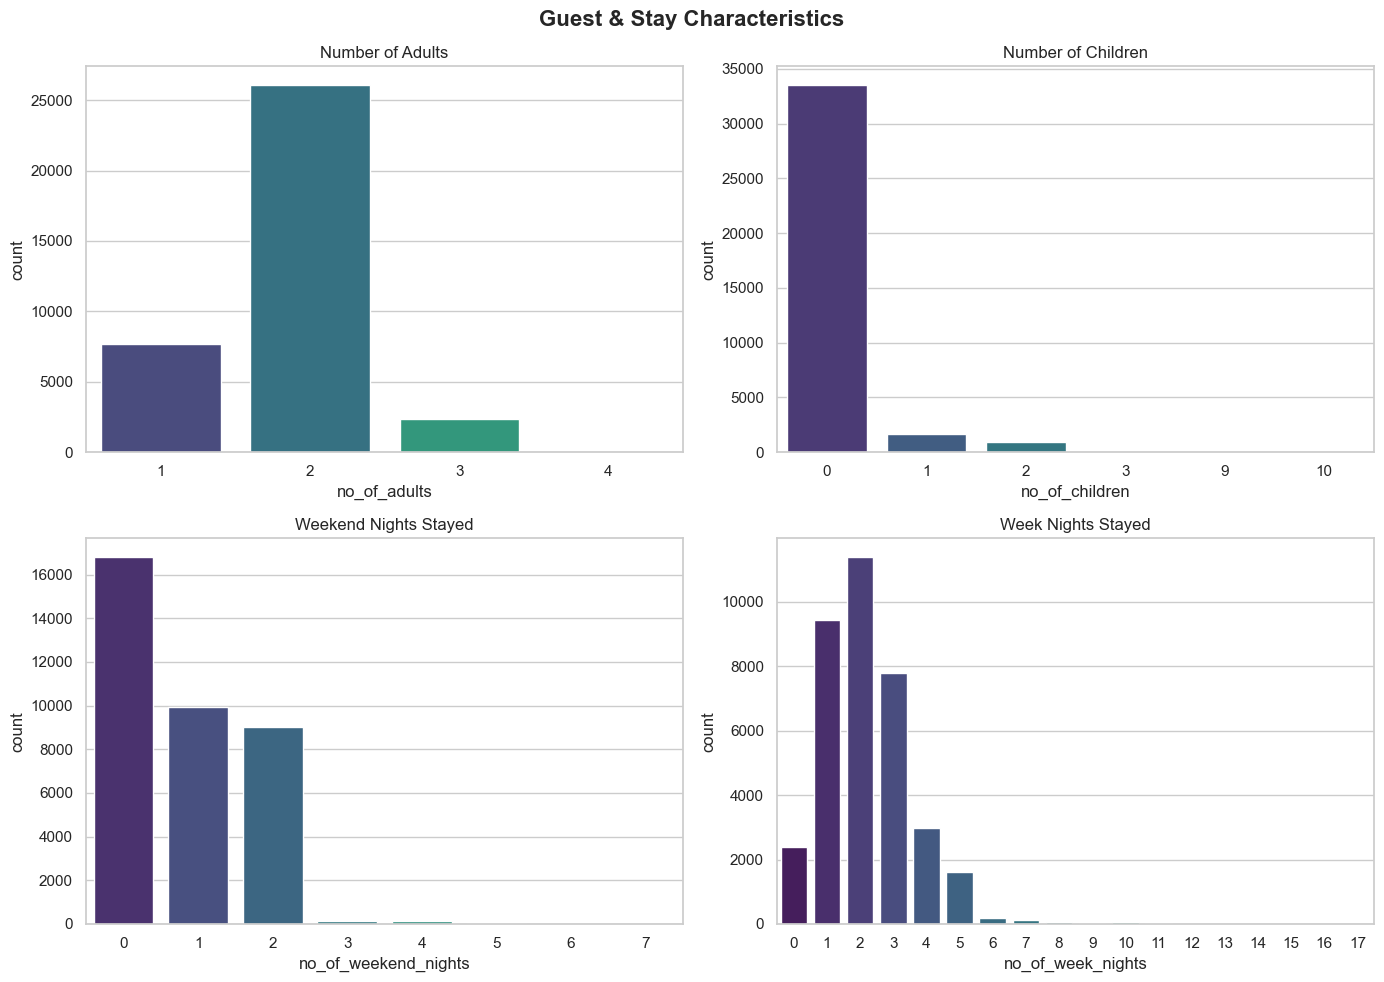

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Guest & Stay Characteristics', fontsize=16, fontweight='bold')

sns.countplot(data=df, x='no_of_adults', ax=axes[0, 0], palette='viridis')
axes[0, 0].set_title('Number of Adults')

sns.countplot(data=df, x='no_of_children', ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('Number of Children')

sns.countplot(
    data=df, x='no_of_weekend_nights', ax=axes[1, 0], palette='viridis'
)
axes[1, 0].set_title('Weekend Nights Stayed')

sns.countplot(data=df, x='no_of_week_nights', ax=axes[1, 1], palette='viridis')
axes[1, 1].set_title('Week Nights Stayed')

plt.tight_layout()
plt.show()

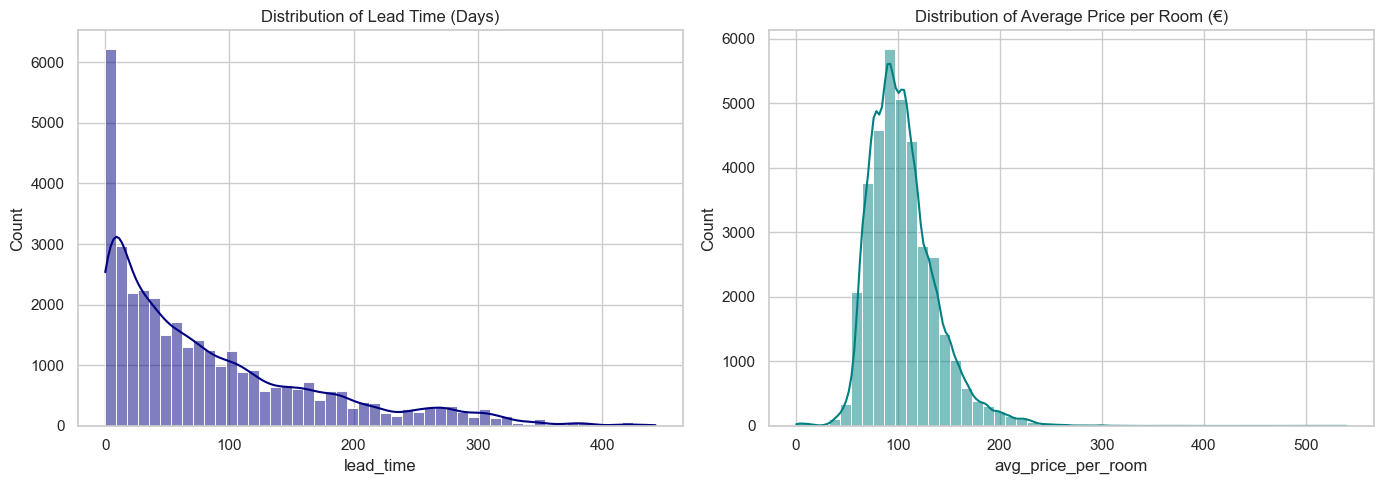

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Lead Time (Days between booking and arrival)
sns.histplot(data=df, x='lead_time', bins=50, kde=True, ax=axes[0], color='navy')
axes[0].set_title('Distribution of Lead Time (Days)')

# Average Room Price
sns.histplot(
    data=df, x='avg_price_per_room', bins=50, kde=True, ax=axes[1], color='teal'
)
axes[1].set_title('Distribution of Average Price per Room (€)')

plt.tight_layout()
plt.show()

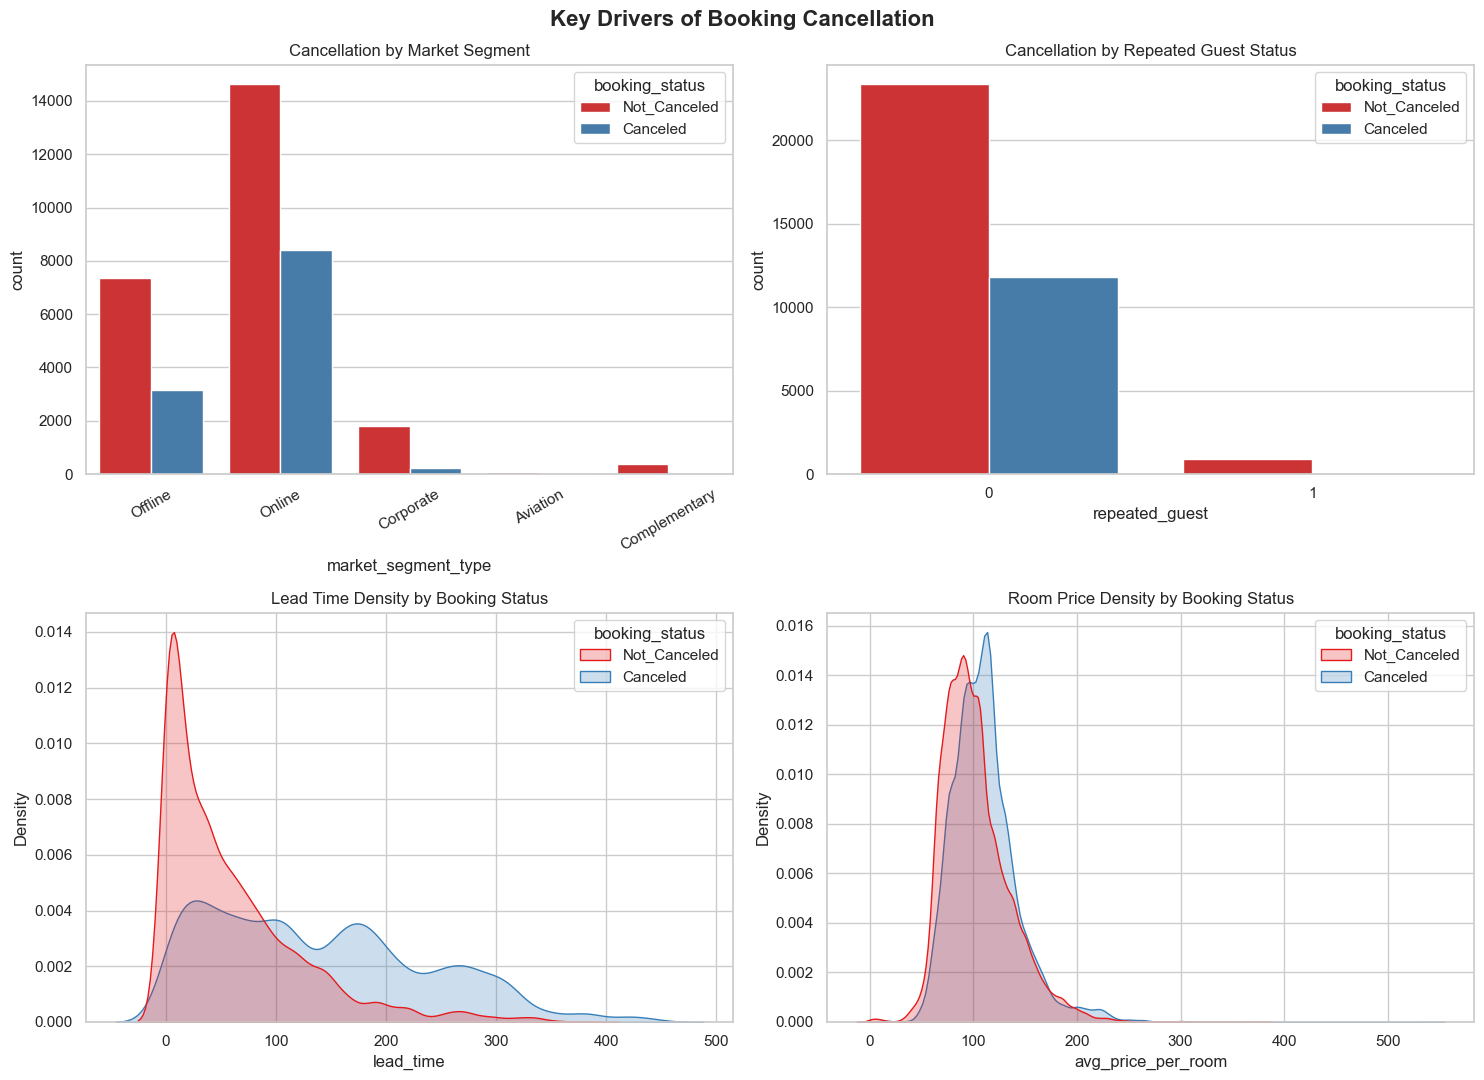

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(
    'Key Drivers of Booking Cancellation', fontsize=16, fontweight='bold'
)

# Market Segment vs Cancellation
sns.countplot(
    data=df,
    x='market_segment_type',
    hue='booking_status',
    ax=axes[0, 0],
    palette='Set1',
)
axes[0, 0].set_title('Cancellation by Market Segment')
axes[0, 0].tick_params(axis='x', rotation=30)

# Repeated Guest vs Cancellation
sns.countplot(
    data=df,
    x='repeated_guest',
    hue='booking_status',
    ax=axes[0, 1],
    palette='Set1',
)
axes[0, 1].set_title('Cancellation by Repeated Guest Status')

# Lead Time Distribution by Booking Status
sns.kdeplot(
    data=df,
    x='lead_time',
    hue='booking_status',
    common_norm=False,
    ax=axes[1, 0],
    palette='Set1',
    fill=True,
)
axes[1, 0].set_title('Lead Time Density by Booking Status')

# Room Price Distribution by Booking Status
sns.kdeplot(
    data=df,
    x='avg_price_per_room',
    hue='booking_status',
    common_norm=False,
    ax=axes[1, 1],
    palette='Set1',
    fill=True,
)
axes[1, 1].set_title('Room Price Density by Booking Status')

plt.tight_layout()
plt.show()

## Feature Engineering, Encoding & Splitting.

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [14]:
# 1. FEATURE ENGINEERING FROM DATE

df['arrival_month'] = df['date_of_arrival'].dt.month
df['arrival_day'] = df['date_of_arrival'].dt.day
df['arrival_dayofweek'] = df['date_of_arrival'].dt.dayofweek

# Drop raw date column now that features are extracted
df.drop(columns=['date_of_arrival'], inplace=True)

In [15]:
# 2. ENCODING CATEGORICAL VARIABLES & TARGET

# Encode target: 'Canceled' -> 1, 'Not_Canceled' -> 0
df['booking_status'] = df['booking_status'].apply(
    lambda x: 1 if str(x).strip().lower() == 'canceled' else 0
)

# Identify nominal categorical columns for One-Hot Encoding
cat_cols = ['type_of_meal_plan', 'room_type_reserved', 'market_segment_type']

# One-hot encode features to prevent implicit ordinal bias
df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True)

In [16]:
X = df_encoded.drop(columns=['booking_status'])
y = df_encoded['booking_status']

In [17]:
# 3. TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [18]:
# 4. FEATURE SCALING

scale_cols = ['lead_time', 'avg_price_per_room']

scaler = StandardScaler()
X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols] = scaler.transform(X_test[scale_cols])

In [19]:
print(f'X_train shape: {X_train.shape}')
print(f'X_test shape:  {X_test.shape}')
print(f'Target balance in train:\n{y_train.value_counts(normalize=True)}')

X_train shape: (28879, 27)
X_test shape:  (7220, 27)
Target balance in train:
booking_status
0    0.672184
1    0.327816
Name: proportion, dtype: float64


## Model Training & Hyperparameter Tuning

In [22]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeClassifier

In [23]:
# 1. Logistic Regression Grid
log_grid = {'C': [0.01, 0.1, 1, 10], 'solver': ['liblinear', 'lbfgs']}
log_search = GridSearchCV(
    LogisticRegression(max_iter=1000, random_state=42),
    log_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
)
log_search.fit(X_train, y_train)

,estimator,LogisticRegre...ndom_state=42)
,param_grid,"{'C': [0.01, 0.1, ...], 'solver': ['liblinear', 'lbfgs']}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,penalty,'l2'


In [24]:
# 2. Decision Tree Grid
dt_grid = {
    'max_depth': [6, 8, 10, 12],
    'min_samples_leaf': [2, 4, 8],
    'criterion': ['gini', 'entropy'],
}
dt_search = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    dt_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
)
dt_search.fit(X_train, y_train)

,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [6, 8, ...], 'min_samples_leaf': [2, 4, ...]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [25]:
# 3. Random Forest Grid
rf_grid = {
    'n_estimators': [100, 200],
    'max_depth': [10, 15, 20],
    'min_samples_split': [2, 5],
}
rf_search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    rf_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1,
)
rf_search.fit(X_train, y_train)

,estimator,RandomForestC...ndom_state=42)
,param_grid,"{'max_depth': [10, 15, ...], 'min_samples_split': [2, 5], 'n_estimators': [100, 200]}"
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,n_estimators,200


In [26]:
print('Best LR Params:', log_search.best_params_)
print('Best DT Params:', dt_search.best_params_)
print('Best RF Params:', rf_search.best_params_)

Best LR Params: {'C': 10, 'solver': 'liblinear'}
Best DT Params: {'criterion': 'gini', 'max_depth': 12, 'min_samples_leaf': 2}
Best RF Params: {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}


In [28]:
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

In [29]:
# Instantiate models using best hyperparameters
best_log = LogisticRegression(
    **log_search.best_params_, max_iter=1000, random_state=42
)
best_dt = DecisionTreeClassifier(**dt_search.best_params_, random_state=42)
best_rf = RandomForestClassifier(**rf_search.best_params_, random_state=42)
hgb_model = HistGradientBoostingClassifier(random_state=42)

In [30]:
# Train all models
best_log.fit(X_train, y_train)
best_dt.fit(X_train, y_train)
best_rf.fit(X_train, y_train)
hgb_model.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,max_iter,100
,max_leaf_nodes,31
,max_depth,None
,min_samples_leaf,20
,l2_regularization,0.0
,max_features,1.0
,max_bins,255
,categorical_features,'from_dtype'
,monotonic_cst,None


## MODEL EVALUATION

In [31]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

In [32]:
models = {
    'Logistic Regression': best_log,
    'Decision Tree': best_dt,
    'Random Forest': best_rf,
    'HistGradientBoosting': hgb_model,
}

In [33]:
results = []
for name, model in models.items():
    preds = model.predict(X_test)
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Precision': precision_score(y_test, preds),
        'Recall': recall_score(y_test, preds),
        'F1-Score': f1_score(y_test, preds),
    })

In [34]:
results_df = pd.DataFrame(results).sort_values(by='F1-Score', ascending=False)
print('Model Performance Benchmark')
print(results_df.to_string(index=False))

Model Performance Benchmark
               Model  Accuracy  Precision   Recall  F1-Score
       Random Forest  0.895152   0.879002 0.788762  0.831441
HistGradientBoosting  0.878393   0.853682 0.759189  0.803667
       Decision Tree  0.873684   0.839477 0.760034  0.797783
 Logistic Regression  0.802770   0.735162 0.622729  0.674291


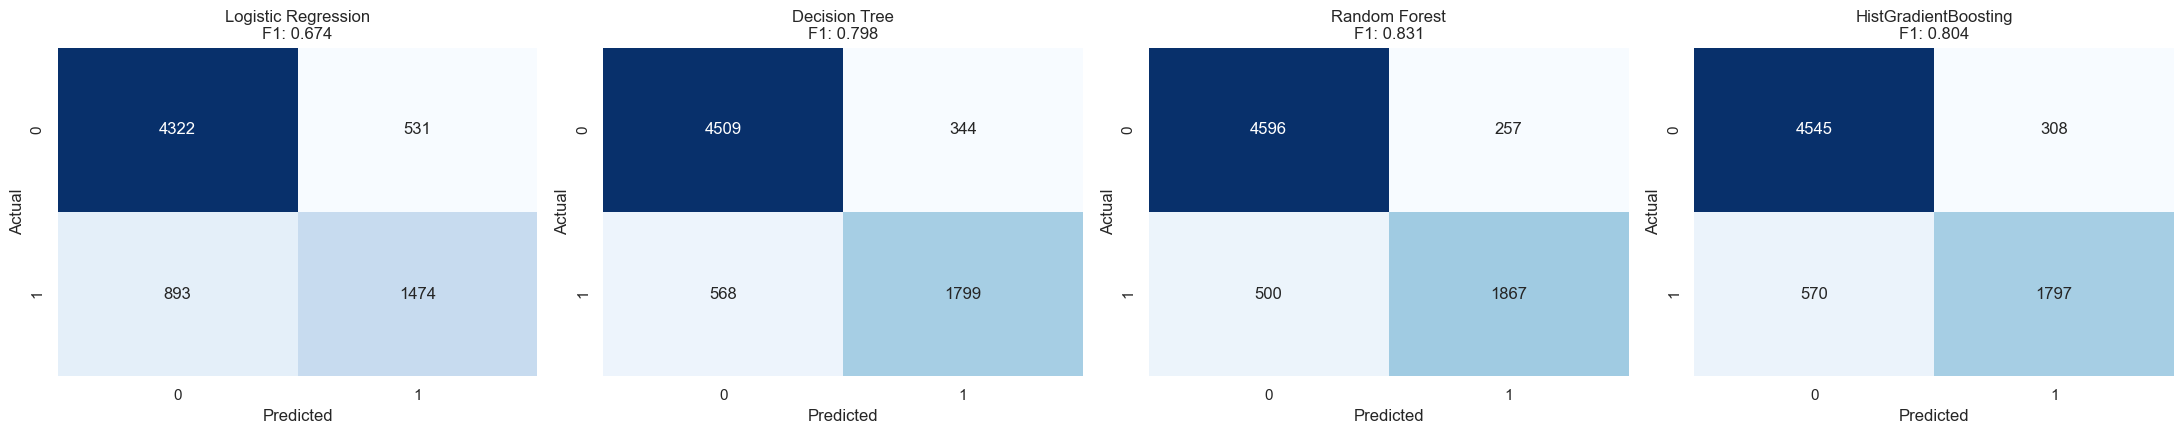

In [35]:
# Plot Confusion Matrices
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    preds = model.predict(X_test)
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False)
    ax.set_title(f'{name}\nF1: {f1_score(y_test, preds):.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

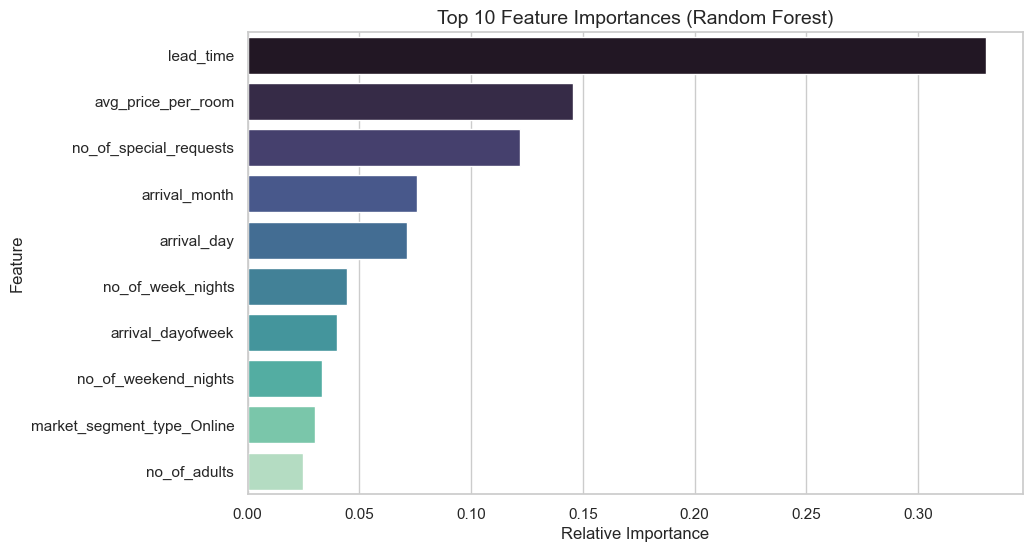

In [36]:
importances = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': best_rf.feature_importances_,
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importances.head(10), x='Importance', y='Feature', palette='mako'
)
plt.title('Top 10 Feature Importances (Random Forest)', fontsize=14)
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()